Exercício 1

In [115]:
import pandas as pd

url = "https://gist.github.com/aishwarya8615/89d9f36fc014dea62487f7347864d16a"
df = pd.read_html(url)[0] 
print(df)

      Unnamed: 0      Country Continent  Year      Status  Life_expectancy  \
0            NaN  Afghanistan      Asia  2015  Developing             65.0   
1            NaN  Afghanistan      Asia  2014  Developing             59.9   
2            NaN  Afghanistan      Asia  2013  Developing             59.9   
3            NaN  Afghanistan      Asia  2012  Developing             59.5   
4            NaN  Afghanistan      Asia  2011  Developing             59.2   
...          ...          ...       ...   ...         ...              ...   
2456         NaN     Zimbabwe    Africa  2004  Developing             44.3   
2457         NaN     Zimbabwe    Africa  2003  Developing             44.5   
2458         NaN     Zimbabwe    Africa  2002  Developing             44.8   
2459         NaN     Zimbabwe    Africa  2001  Developing             45.3   
2460         NaN     Zimbabwe    Africa  2000  Developing             46.0   

      Adult_Mortality  infant_deaths  Alcohol  percentage_expen

In [116]:
print(df.shape[0]) #Número de linhas
print(df.shape[1]) #Número de colunas (features)

2461
24


In [117]:
#Agora vamos remover a primeira coluna
df = df.drop(df.columns[[0]], axis = 1)
print(df)
print(df.shape[1])

          Country Continent  Year      Status  Life_expectancy  \
0     Afghanistan      Asia  2015  Developing             65.0   
1     Afghanistan      Asia  2014  Developing             59.9   
2     Afghanistan      Asia  2013  Developing             59.9   
3     Afghanistan      Asia  2012  Developing             59.5   
4     Afghanistan      Asia  2011  Developing             59.2   
...           ...       ...   ...         ...              ...   
2456     Zimbabwe    Africa  2004  Developing             44.3   
2457     Zimbabwe    Africa  2003  Developing             44.5   
2458     Zimbabwe    Africa  2002  Developing             44.8   
2459     Zimbabwe    Africa  2001  Developing             45.3   
2460     Zimbabwe    Africa  2000  Developing             46.0   

      Adult_Mortality  infant_deaths  Alcohol  percentage_expenditure  \
0                 263             62     0.01               71.279624   
1                 271             64     0.01               7

(np.float64(-1.1541226042849213),
 np.float64(1.0458772849367681),
 np.float64(-1.1882920458674502),
 np.float64(1.1042043831367474))

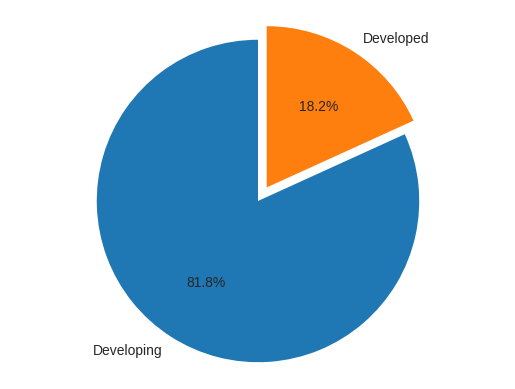

In [118]:
import matplotlib.pyplot as plt 

status_counts = df['Status'].value_counts()
labels = status_counts.index
sizes = status_counts.values

fig, ax = plt.subplots()
ax.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, explode = [0.1,0.0])
ax.axis('equal') 

Exercício 2

In [119]:
#Convertendo o conteúdo da coluna Life_expectancy em um array
import numpy as np

Life_expectancy = df['Life_expectancy'].to_numpy()
print(Life_expectancy)

[65.  59.9 59.9 ... 44.8 45.3 46. ]


In [120]:
m = np.mean(Life_expectancy) #Função para calcular a média
md = np.median(Life_expectancy) #Função para calcular a mediana
var = np.var(Life_expectancy) #Função para calcular a variância. Por padrão é calculada a variância populacional
print("A média é:", m)
print("A mediana é:", md)
print("A variância é:", var)

A média é: 69.46456724908573
A mediana é: 72.3
A variância é: 92.87998791715574


$$ \sigma^2 = \frac{\sum_{i=1}^{N} (x_i - \mu)^2}{N} $$
<center>Variância Populacional</center>

In [121]:
#Podemos também calcular a variância amostral
var_a = np.var(Life_expectancy, ddof=1)
print("Variância amostral:", var_a)
print("Desvio Padrão:", np.sqrt(var_a))

Variância amostral: 92.91774400980499
Desvio Padrão: 9.639385043134494


$$ \sigma^2 = \frac{\sum_{i=1}^{N} (x_i - \mu)^2}{N - 1} $$
<center>Variância Amostral</center>

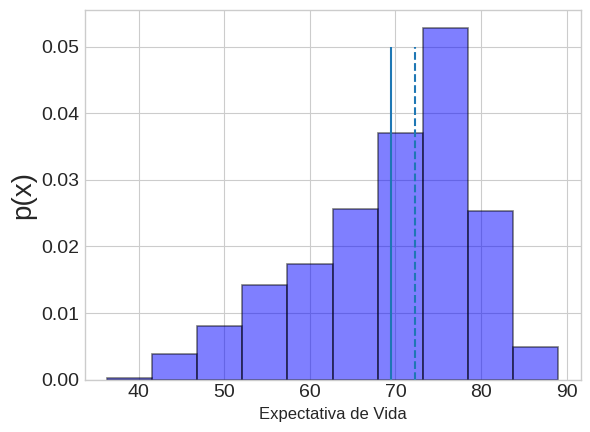

In [122]:
n, bins, patches = plt.hist(Life_expectancy, facecolor='blue', alpha=0.5, density=True, edgecolor='black', linewidth=1.2)
plt.vlines(m, 0, 0.05)
plt.vlines(md, 0, 0.05, linestyles='dashed')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("Expectativa de Vida", fontsize=12)
plt.ylabel("p(x)", fontsize=20)
plt.show(True)

Exercício 3

In [123]:
countries = ["Ireland", "Finland", "Netherlands", "Zambia", "Angola"]
#Vamos filtrar nosso data frame apenas para os países de interesse
#O comando df["Country"] seleciona o atributo "Country" do nsso data frame original
#A função isin(countries) é quem realiza a selação, se o paś do atributo Country estiver na lista countries 
#ela retorna True, caso não esteja ela retorna False
df_filtered = df[df["Country"].isin(countries)]
print(df_filtered)

     Country Continent  Year      Status  Life_expectancy  Adult_Mortality  \
48    Angola    Africa  2015  Developing             52.4              335   
49    Angola    Africa  2014  Developing             51.7              348   
50    Angola    Africa  2013  Developing             51.1              355   
51    Angola    Africa  2012  Developing             56.0              358   
52    Angola    Africa  2011  Developing             51.0              361   
...      ...       ...   ...         ...              ...              ...   
2440  Zambia    Africa  2004  Developing             47.9              578   
2441  Zambia    Africa  2003  Developing             46.4               64   
2442  Zambia    Africa  2002  Developing             45.5               69   
2443  Zambia    Africa  2001  Developing             44.6              611   
2444  Zambia    Africa  2000  Developing             43.8              614   

      infant_deaths  Alcohol  percentage_expenditure  Hepatitis

In [124]:
df_Ireland = df_filtered[df_filtered['Country'] == "Ireland"]
df_Finland = df_filtered[df_filtered['Country'] == "Finland"]
df_Netherlands = df_filtered[df_filtered['Country'] == "Netherlands"]
df_Zambia = df_filtered[df_filtered['Country'] == "Zambia"]
df_Angola = df_filtered[df_filtered['Country'] == "Angola"]  
print(df_Zambia)

     Country Continent  Year      Status  Life_expectancy  Adult_Mortality  \
2429  Zambia    Africa  2015  Developing             61.8               33   
2430  Zambia    Africa  2014  Developing             61.1              314   
2431  Zambia    Africa  2013  Developing             63.0              328   
2432  Zambia    Africa  2012  Developing             59.2              349   
2433  Zambia    Africa  2011  Developing             58.2              366   
2434  Zambia    Africa  2010  Developing             58.0              363   
2435  Zambia    Africa  2009  Developing             57.4              368   
2436  Zambia    Africa  2008  Developing             55.7               45   
2437  Zambia    Africa  2007  Developing             52.6              487   
2438  Zambia    Africa  2006  Developing             58.0              526   
2439  Zambia    Africa  2005  Developing             49.3              554   
2440  Zambia    Africa  2004  Developing             47.9       

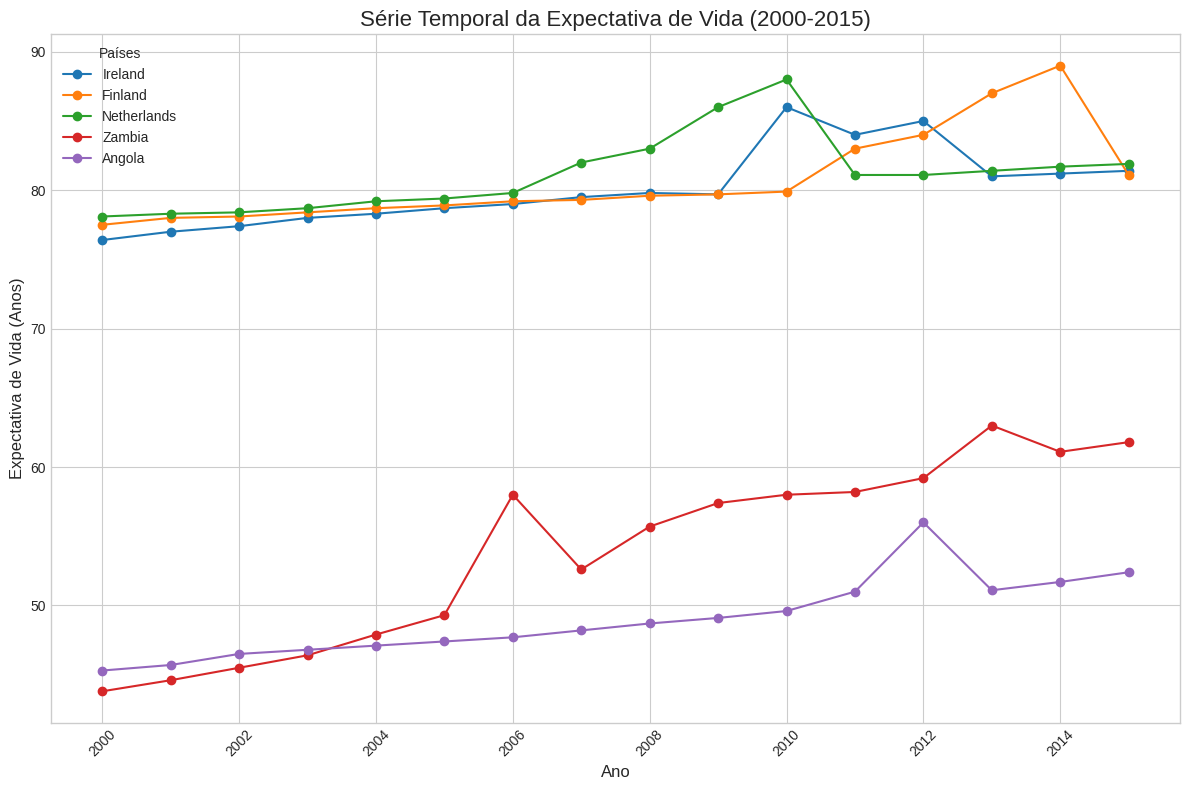

In [125]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(12, 8))
plt.plot(df_Ireland['Year'], df_Ireland['Life_expectancy'], marker='o', linestyle='-', label="Ireland")
plt.plot(df_Finland['Year'], df_Finland['Life_expectancy'], marker='o', linestyle='-', label="Finland")
plt.plot(df_Netherlands['Year'], df_Netherlands['Life_expectancy'], marker='o', linestyle='-', label="Netherlands")
plt.plot(df_Zambia['Year'], df_Zambia['Life_expectancy'], marker='o', linestyle='-', label="Zambia")
plt.plot(df_Angola['Year'], df_Angola['Life_expectancy'], marker='o', linestyle='-', label="Angola")

plt.title('Série Temporal da Expectativa de Vida (2000-2015)', fontsize=16)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Expectativa de Vida (Anos)', fontsize=12)
plt.legend(title='Países', fontsize=10)
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show(True)

Exercício 4

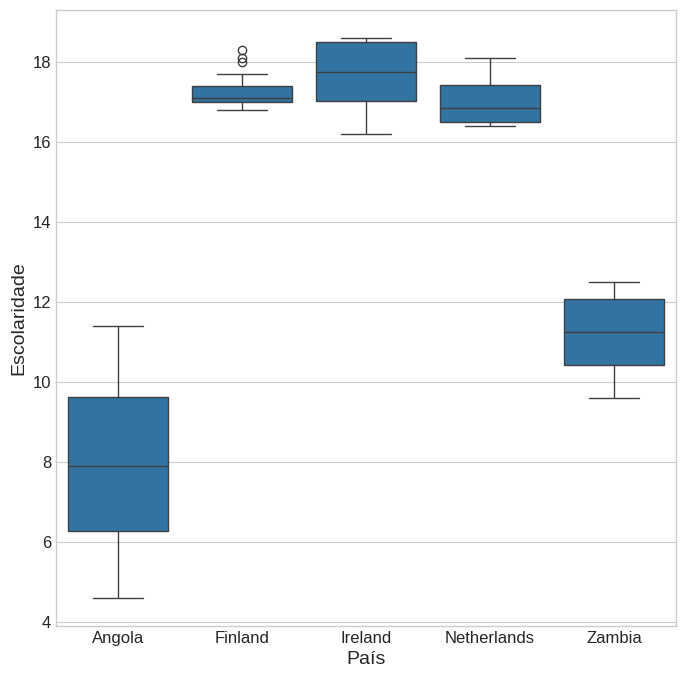

In [126]:
import seaborn as sns

plt.figure(figsize=(8, 8))
sns.boxplot(x="Country", y="Schooling", data=df_filtered)
plt.xlabel('País', fontsize=14)
plt.ylabel('Escolaridade', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show(True)

In [127]:
School_Iren = df_Ireland['Schooling'].to_numpy()
School_Fin = df_Finland['Schooling'].to_numpy()
School_Nether = df_Netherlands['Schooling'].to_numpy()
School_Zambia = df_Zambia['Schooling'].to_numpy()
School_Ango = df_Angola['Schooling'].to_numpy()
print("A mediana da escolaridade da Irlanda é", np.median(School_Iren))
print("A mediana da escolaridade da Finlândia é", np.median(School_Fin))
print("A mediana da escolaridade dos Países Baixos é", np.median(School_Nether))
print("A mediana da escolaridade da Zambia é", np.median(School_Zambia))
print("A mediana da escolaridade da Angola é", np.median(School_Ango))

A mediana da escolaridade da Irlanda é 17.75
A mediana da escolaridade da Finlândia é 17.1
A mediana da escolaridade dos Países Baixos é 16.85
A mediana da escolaridade da Zambia é 11.25
A mediana da escolaridade da Angola é 7.9


Exercício 5

In [128]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
url = "https://www.worldometers.info/world-population/population-by-country/" 

# Send a GET request to the URL
response = requests.get(url)

print(response)

<Response [200]>


In [129]:
# Parse the HTML content with BeautifulSoup
soup = BeautifulSoup(response.content, 'html.parser') 

In [130]:
# Find the table containing the population data (find the first table)
table = soup.find('table') 

In [131]:
# Convert the table to a Pandas DataFrame
df_5 = pd.read_html(str(table))[0]
print(df_5)

       # Country (or dependency)  Population 2025 Yearly Change  Net Change  \
0      1                   India       1463865525         0.89%    12929734   
1      2                   China       1416096094        −0.23%  −3,225,184   
2      3           United States        347275807         0.54%     1849236   
3      4               Indonesia        285721236         0.79%     2233305   
4      5                Pakistan        255219554         1.57%     3950390   
..   ...                     ...              ...           ...         ...   
228  229              Montserrat             4359        −0.68%         −30   
229  230        Falkland Islands             3469        −0.03%          −1   
230  231                 Tokelau             2608         4.07%         102   
231  232                    Niue             1821         0.11%           2   
232  233                Holy See              501         1.01%           5   

     Density (P/Km²)  Land Area (Km²) Migrants (net

/tmp/ipykernel_419/1243177714.py:2: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  df_5 = pd.read_html(str(table))[0]


In [132]:
print(df_5.shape)

(233, 12)


In [133]:
#Será necessário remover a primeira e a segunda coluna
df_5 = df_5.drop(df_5.columns[[0, 1]], axis=1)
print(df_5)
print(df_5.shape)

     Population 2025 Yearly Change  Net Change  Density (P/Km²)  \
0         1463865525         0.89%    12929734              492   
1         1416096094        −0.23%  −3,225,184              151   
2          347275807         0.54%     1849236               38   
3          285721236         0.79%     2233305              158   
4          255219554         1.57%     3950390              331   
..               ...           ...         ...              ...   
228             4359        −0.68%         −30               44   
229             3469        −0.03%          −1                0   
230             2608         4.07%         102              261   
231             1821         0.11%           2                7   
232              501         1.01%           5             1253   

     Land Area (Km²) Migrants (net)  Fert. Rate  Median Age Urban Pop %  \
0            2973190       −495,753        1.94        28.8       37.1%   
1            9388211       −268,126        1.

In [134]:
# Remove caracteres não numéricos e converte para float/int
for col in df_5.columns:  # pula '#' e 'Country'
    df_5[col] = df_5[col].astype(str).str.replace(r'[, %]', '', regex=True)
    df_5[col] = pd.to_numeric(df_5[col], errors='coerce')

In [135]:
#Agora vamos calcular a matriz de correlação
corr = df_5.corr(numeric_only=True)
print(corr)

                 Population 2025  Yearly Change  Net Change  Density (P/Km²)  \
Population 2025         1.000000      -0.042425    0.928537        -0.025402   
Yearly Change          -0.042425       1.000000    0.153312        -0.121136   
Net Change              0.928537       0.153312    1.000000        -0.034565   
Density (P/Km²)        -0.025402      -0.121136   -0.034565         1.000000   
Land Area (Km²)         0.448457      -0.042741    0.271457        -0.058213   
Migrants (net)          0.577406       0.149837    0.478663        -0.060029   
Fert. Rate             -0.032182       0.747059    0.192366        -0.125565   
Median Age             -0.013868      -0.668436   -0.198920         0.181592   
Urban Pop %            -0.036269      -0.270683   -0.181275         0.126356   
World Share             0.999999      -0.042364    0.928574        -0.025432   

                 Land Area (Km²)  Migrants (net)  Fert. Rate  Median Age  \
Population 2025         0.448457        0.5

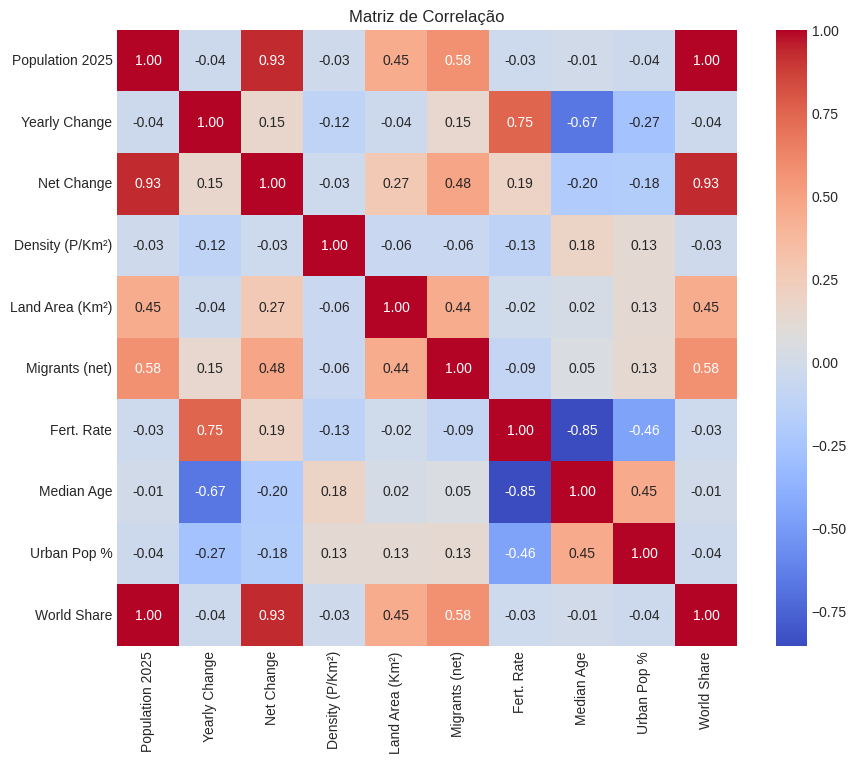

In [136]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de Correlação")
plt.show(True)